Dataset shape: (6433, 21)
Columns: ['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls', 'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough', 'pickup_hour', 'pickup_weekday', 'pickup_date', 'duration_min', 'day_period', 'passenger_group', 'distance_group']


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,...,dropoff_zone,pickup_borough,dropoff_borough,pickup_hour,pickup_weekday,pickup_date,duration_min,day_period,passenger_group,distance_group
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,...,UN/Turtle Bay South,Manhattan,Manhattan,20,Saturday,2019-03-23,6.250000,Evening,1 passenger,Short (<=2 mi)
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,...,Upper West Side South,Manhattan,Manhattan,16,Monday,2019-03-04,7.083333,Day,1 passenger,Short (<=2 mi)
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,...,West Village,Manhattan,Manhattan,17,Wednesday,2019-03-27,7.400000,Day,1 passenger,Short (<=2 mi)
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,...,Yorkville West,Manhattan,Manhattan,1,Sunday,2019-03-10,25.866667,Night,1 passenger,Long (>5 mi)
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,...,Yorkville West,Manhattan,Manhattan,13,Saturday,2019-03-30,9.533333,Day,3+ passengers,Medium (2-5 mi)


,missing_values
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


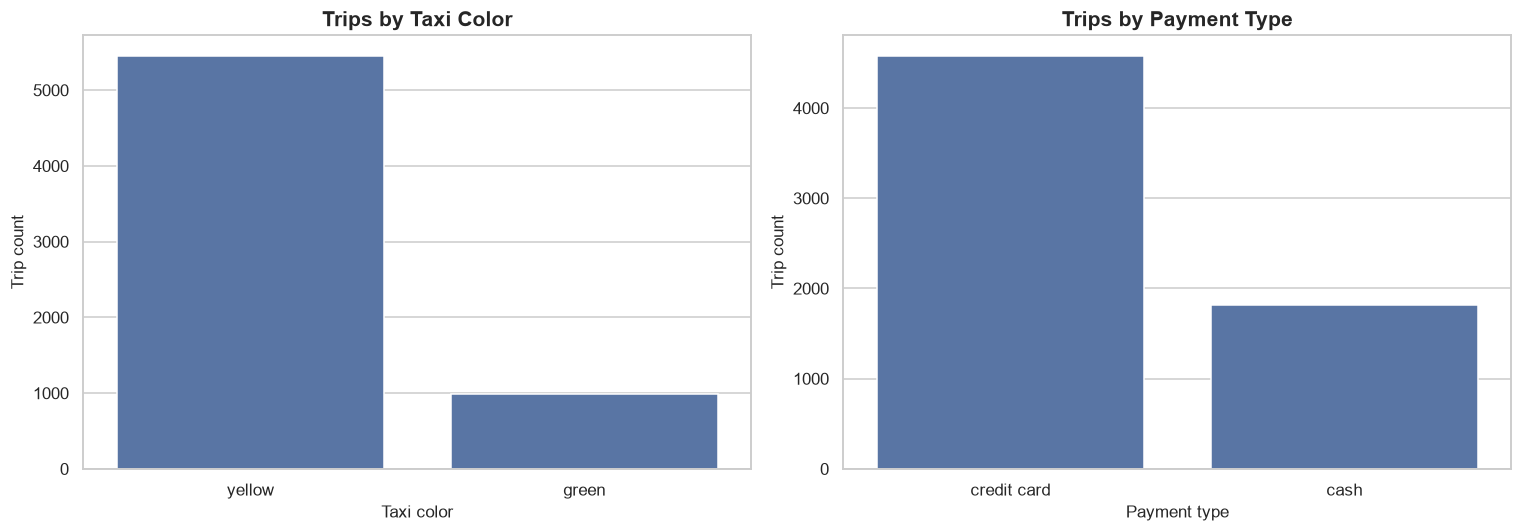

In [1]:
# If needed, install packages in a separate cell:
# %pip install seaborn pandas numpy matplotlib scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11
})

OUTPUT_DIR = Path("taxi_analysis_output")
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

df = sns.load_dataset("taxis")
data = df.copy()

for col in ["pickup", "dropoff"]:
    data[col] = pd.to_datetime(data[col], errors="coerce")

for col in ["passengers", "distance", "fare", "tip", "tolls", "total"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data["pickup_hour"] = data["pickup"].dt.hour
data["pickup_weekday"] = data["pickup"].dt.day_name()
data["pickup_date"] = data["pickup"].dt.date
data["duration_min"] = (data["dropoff"] - data["pickup"]).dt.total_seconds() / 60
data["day_period"] = np.select(
    [data["pickup_hour"].between(6, 17), data["pickup_hour"].between(18, 23)],
    ["Day", "Evening"], default="Night"
)
data["passenger_group"] = pd.cut(
    data["passengers"], bins=[-0.1, 1, 2, np.inf],
    labels=["1 passenger", "2 passengers", "3+ passengers"]
)
data["distance_group"] = pd.cut(
    data["distance"], bins=[-0.001, 2, 5, np.inf],
    labels=["Short (<=2 mi)", "Medium (2-5 mi)", "Long (>5 mi)"]
)

print("Dataset shape:", data.shape)
print("Columns:", data.columns.tolist())
display(data.head())
display(data.isna().sum().rename("missing_values").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=data, x="color", order=data["color"].value_counts().index, ax=axes[0])
axes[0].set_title("Trips by Taxi Color")
axes[0].set_xlabel("Taxi color")
axes[0].set_ylabel("Trip count")

sns.countplot(data=data, x="payment", order=data["payment"].value_counts().index, ax=axes[1])
axes[1].set_title("Trips by Payment Type")
axes[1].set_xlabel("Payment type")
axes[1].set_ylabel("Trip count")
plt.tight_layout()
plt.show()

,trip_count
passenger_group,
1 passenger,4774
2 passengers,876
3+ passengers,783


Average passengers per trip: 1.54
Maximum passenger count: 6


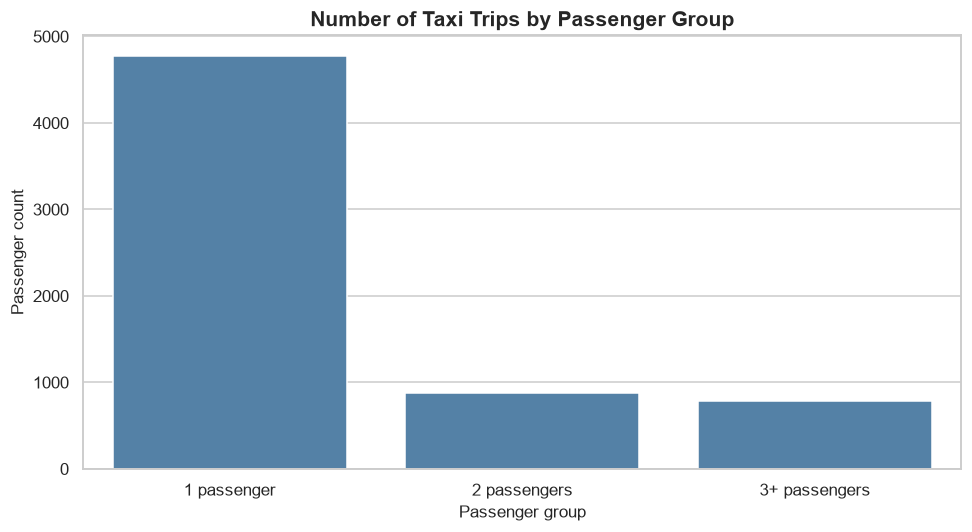

,fare,tip,distance,total
passenger_group,,,,
1 passenger,13.03,1.93,3.02,18.34
2 passengers,13.17,2.10,2.98,18.91
3+ passengers,13.37,2.13,3.12,19.16


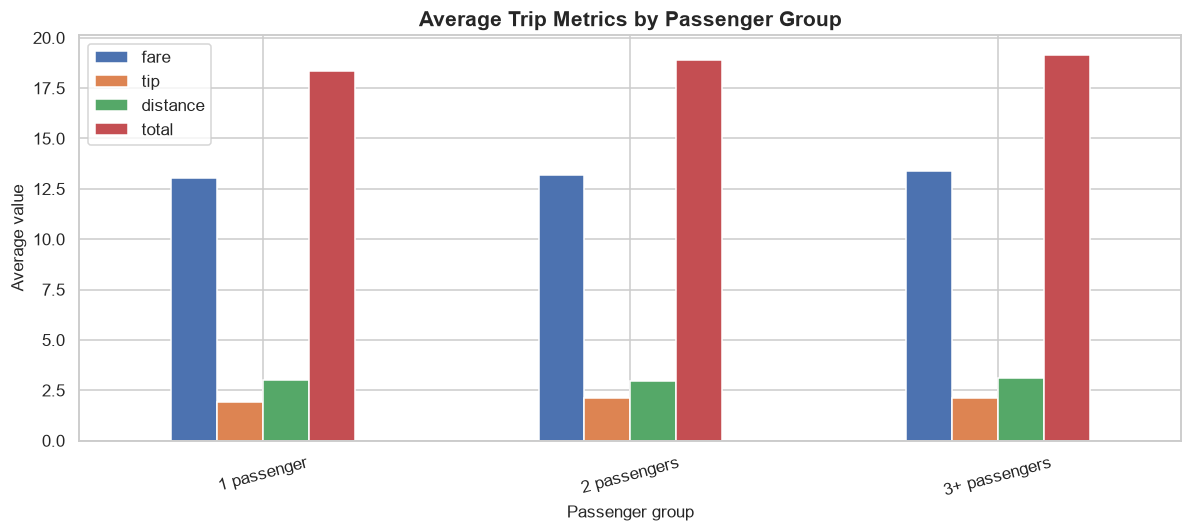

In [2]:
passenger_data = data.dropna(subset=["passenger_group"]).copy()

passenger_counts = passenger_data["passenger_group"].value_counts().reindex(
    ["1 passenger", "2 passengers", "3+ passengers"]
)
display(passenger_counts.rename("trip_count").to_frame())
print("Average passengers per trip:", round(passenger_data["passengers"].mean(), 2))
print("Maximum passenger count:", passenger_data["passengers"].max())

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=passenger_counts.index, y=passenger_counts.values, color="steelblue", ax=ax)
ax.set_title("Number of Taxi Trips by Passenger Group")
ax.set_xlabel("Passenger group")
ax.set_ylabel("Passenger count")
plt.tight_layout()
plt.show()

passenger_means = passenger_data.groupby("passenger_group", observed=False)[
    ["fare", "tip", "distance", "total"]
].mean()
display(passenger_means.round(2))

passenger_means.plot(kind="bar", figsize=(11, 5))
plt.title("Average Trip Metrics by Passenger Group")
plt.xlabel("Passenger group")
plt.ylabel("Average value")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

,distance_miles
count,6433.000000
mean,3.024617
median,1.640000
min,0.000000
max,36.700000
std,3.827867


,trip_count
distance_group,
Short (<=2 mi),3805
Medium (2-5 mi),1668
Long (>5 mi),960


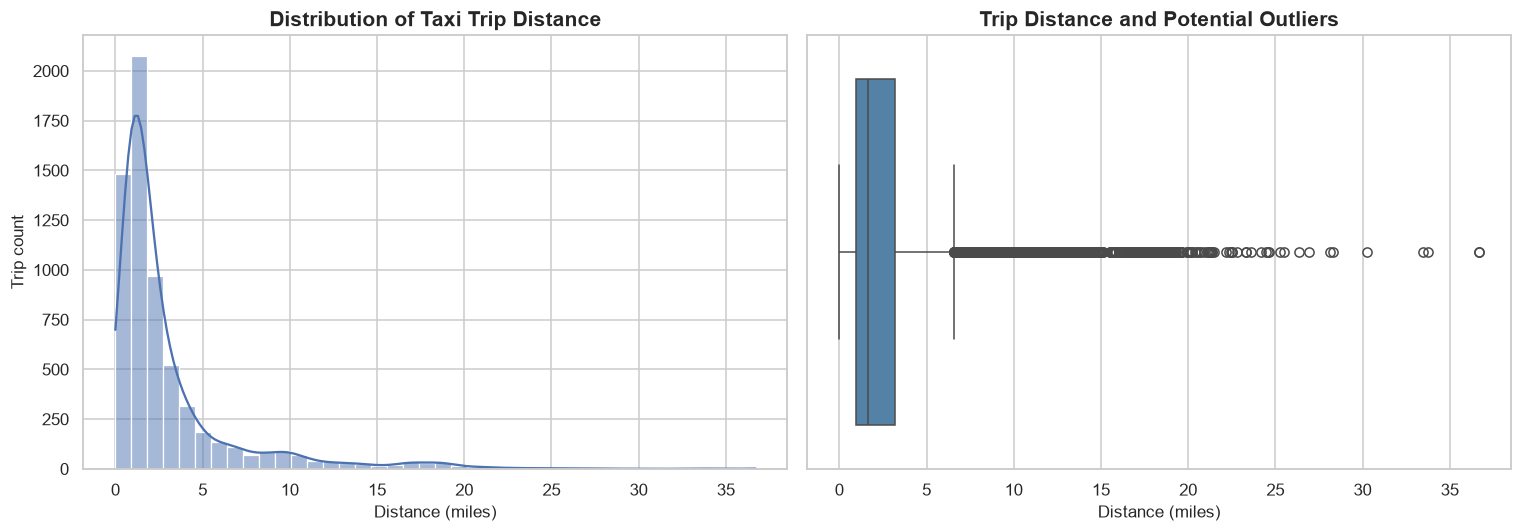

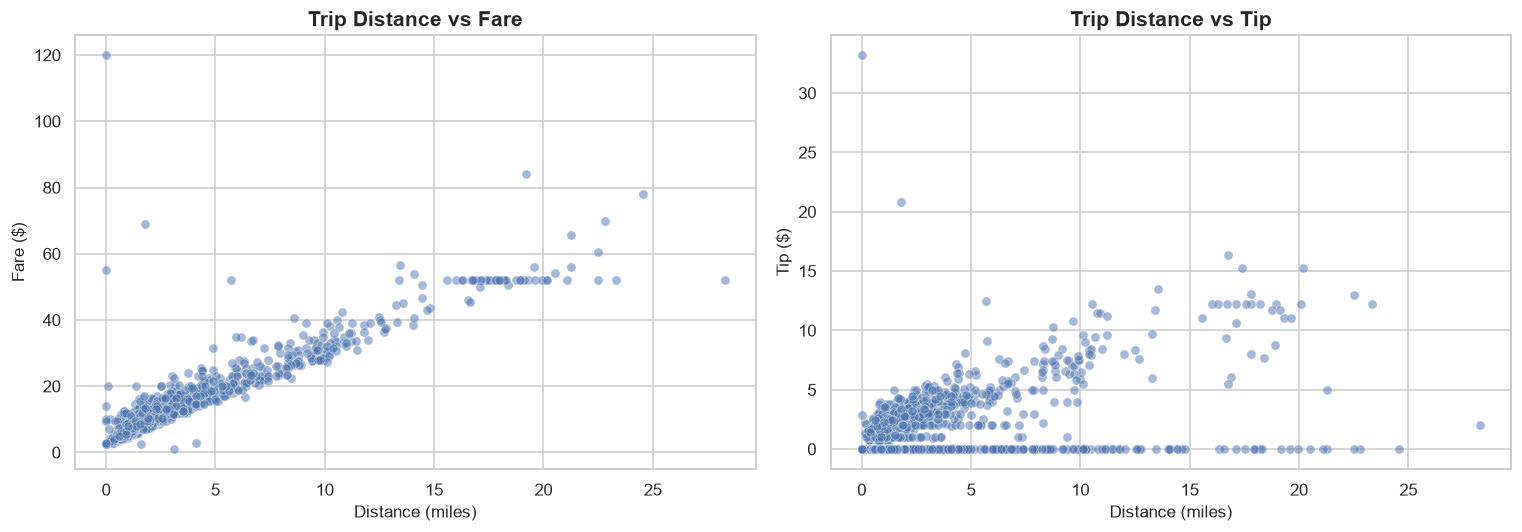

,fare,tip,total
distance_group,,,
Short (<=2 mi),7.42,1.34,11.95
Medium (2-5 mi),14.01,2.13,19.35
Long (>5 mi),33.98,4.26,43.11


In [3]:
distance_data = data.dropna(subset=["distance"]).copy()

display(distance_data["distance"].agg(["count", "mean", "median", "min", "max", "std"]).to_frame("distance_miles"))
distance_counts = distance_data["distance_group"].value_counts().reindex(
    ["Short (<=2 mi)", "Medium (2-5 mi)", "Long (>5 mi)"]
)
display(distance_counts.rename("trip_count").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(distance_data["distance"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Taxi Trip Distance")
axes[0].set_xlabel("Distance (miles)")
axes[0].set_ylabel("Trip count")
sns.boxplot(x=distance_data["distance"], color="steelblue", ax=axes[1])
axes[1].set_title("Trip Distance and Potential Outliers")
axes[1].set_xlabel("Distance (miles)")
plt.tight_layout()
plt.show()

sample = distance_data.sample(min(1600, len(distance_data)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=sample, x="distance", y="fare", alpha=.5, ax=axes[0])
axes[0].set_title("Trip Distance vs Fare")
axes[0].set_xlabel("Distance (miles)")
axes[0].set_ylabel("Fare ($)")
sns.scatterplot(data=sample, x="distance", y="tip", alpha=.5, ax=axes[1])
axes[1].set_title("Trip Distance vs Tip")
axes[1].set_xlabel("Distance (miles)")
axes[1].set_ylabel("Tip ($)")
plt.tight_layout()
plt.show()

display(distance_data.groupby("distance_group", observed=False)[["fare", "tip", "total"]].mean().round(2))

,fare
count,6433.000000
sum,84214.870000
mean,13.091073
median,9.500000
min,1.000000
max,150.000000


,trip_count
fare_band,
<= $10,3619
$10-$20,1863
$20-$40,681
> $40,270


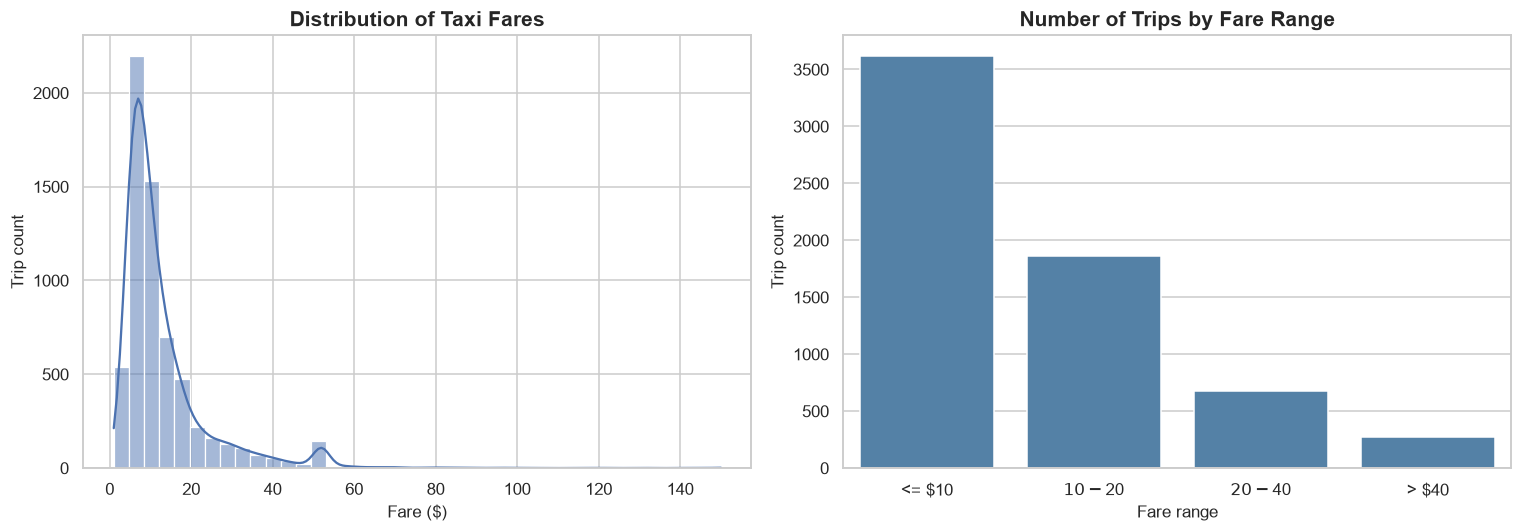

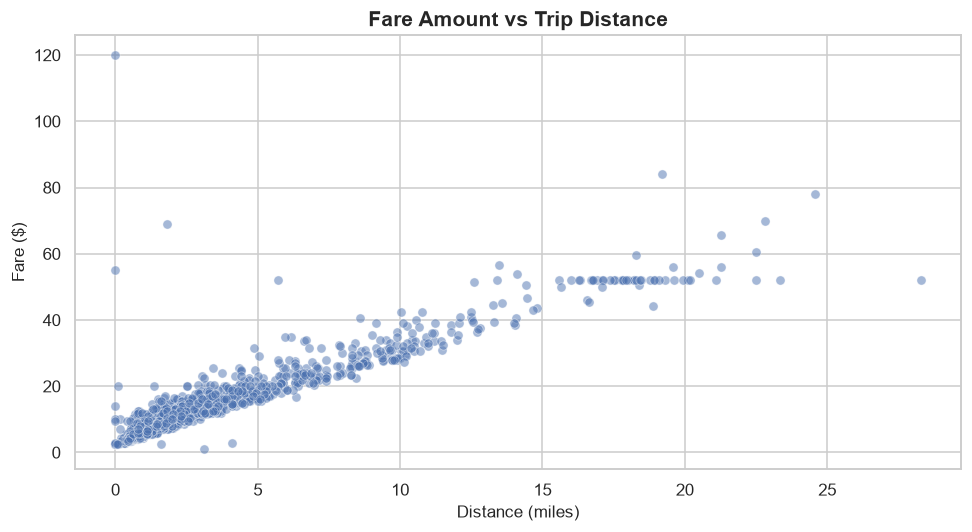

,count,mean,median
passenger_group,,,
1 passenger,4774,13.03,9.5
2 passengers,876,13.17,9.0
3+ passengers,783,13.37,9.5


In [4]:
fare_data = data.dropna(subset=["fare"]).copy()

display(fare_data["fare"].agg(["count", "sum", "mean", "median", "min", "max"]).to_frame("fare"))
fare_data["fare_band"] = pd.cut(
    fare_data["fare"], bins=[-np.inf, 10, 20, 40, np.inf],
    labels=["<= $10", "$10-$20", "$20-$40", "> $40"]
)
fare_counts = fare_data["fare_band"].value_counts().sort_index()
display(fare_counts.rename("trip_count").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(fare_data["fare"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Taxi Fares")
axes[0].set_xlabel("Fare ($)")
axes[0].set_ylabel("Trip count")
sns.barplot(x=fare_counts.index, y=fare_counts.values, color="steelblue", ax=axes[1])
axes[1].set_title("Number of Trips by Fare Range")
axes[1].set_xlabel("Fare range")
axes[1].set_ylabel("Trip count")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=fare_data.sample(min(1800, len(fare_data)), random_state=42),
                x="distance", y="fare", alpha=.5, ax=ax)
ax.set_title("Fare Amount vs Trip Distance")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Fare ($)")
plt.tight_layout()
plt.show()

display(fare_data.groupby("passenger_group", observed=False)["fare"].agg(
    ["count", "mean", "median"]
).round(2))

Total tips: 12732.32
Mean tip: 1.98
Median tip: 1.7
Maximum tip: 33.2
Trips with positive tips (%): 64.08
Mean tip as % of fare: 16.92


,trip_count
tip_status,
Positive tip,4122
Zero tip,2311


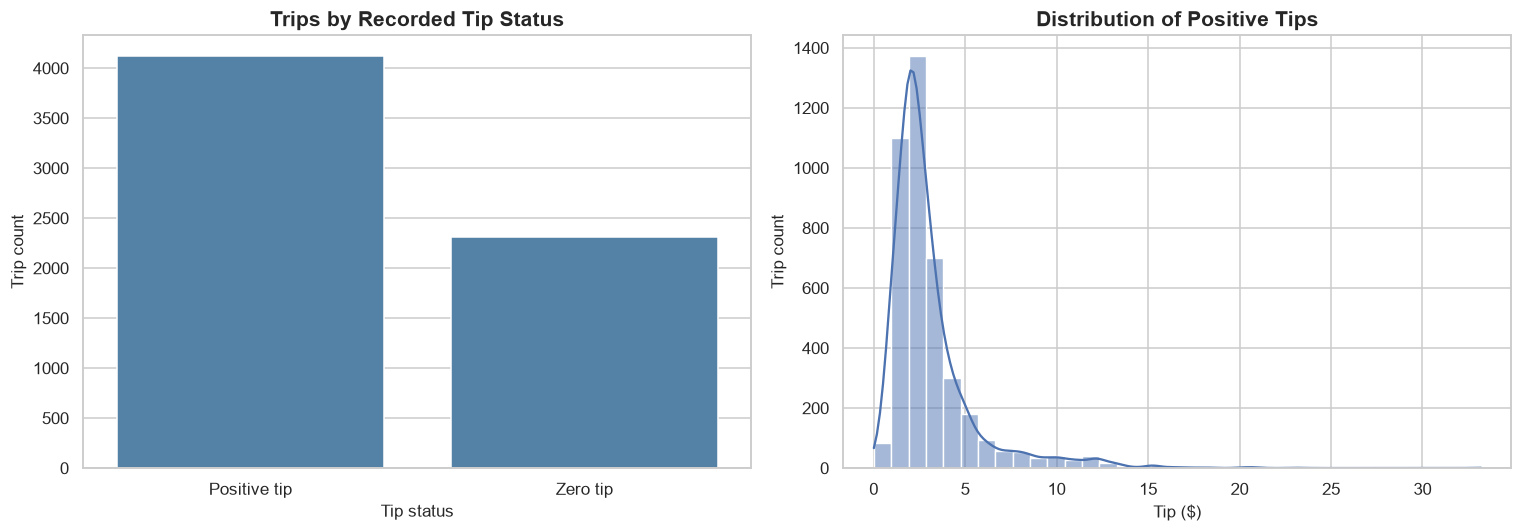

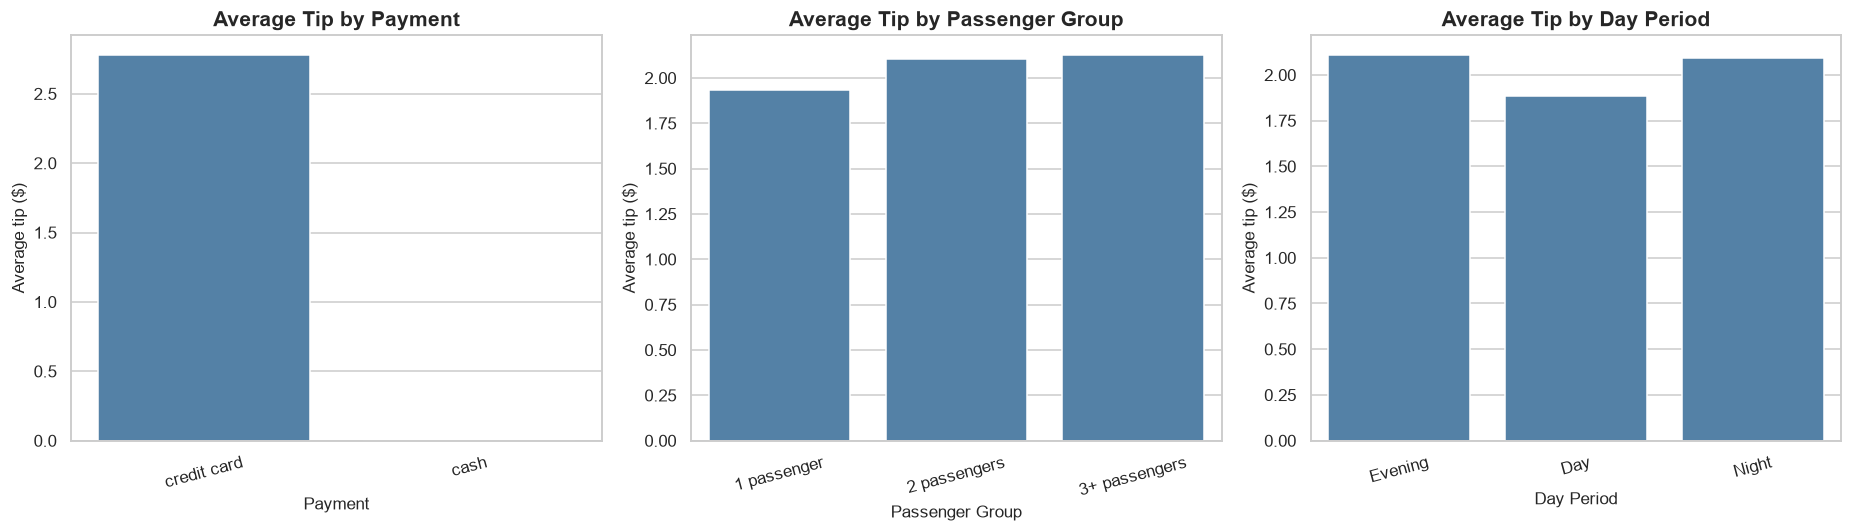

In [5]:
tip_data = data.dropna(subset=["tip"]).copy()
tip_data["tip_status"] = np.where(tip_data["tip"] > 0, "Positive tip", "Zero tip")
tip_data["tip_percent_of_fare"] = 100 * tip_data["tip"] / tip_data["fare"].replace(0, np.nan)

print("Total tips:", round(tip_data["tip"].sum(), 2))
print("Mean tip:", round(tip_data["tip"].mean(), 2))
print("Median tip:", round(tip_data["tip"].median(), 2))
print("Maximum tip:", round(tip_data["tip"].max(), 2))
print("Trips with positive tips (%):", round((tip_data["tip"] > 0).mean() * 100, 2))
print("Mean tip as % of fare:", round(tip_data["tip_percent_of_fare"].replace(
    [np.inf, -np.inf], np.nan).mean(), 2))

tip_counts = tip_data["tip_status"].value_counts()
display(tip_counts.rename("trip_count").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=tip_counts.index, y=tip_counts.values, color="steelblue", ax=axes[0])
axes[0].set_title("Trips by Recorded Tip Status")
axes[0].set_xlabel("Tip status")
axes[0].set_ylabel("Trip count")
sns.histplot(tip_data.loc[tip_data["tip"] > 0, "tip"], bins=35, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Positive Tips")
axes[1].set_xlabel("Tip ($)")
axes[1].set_ylabel("Trip count")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, ["payment", "passenger_group", "day_period"]):
    sns.barplot(data=tip_data, x=col, y="tip", errorbar=None, color="steelblue", ax=ax)
    ax.set_title(f"Average Tip by {col.replace('_', ' ').title()}")
    ax.set_xlabel(col.replace("_", " ").title())
    ax.set_ylabel("Average tip ($)")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

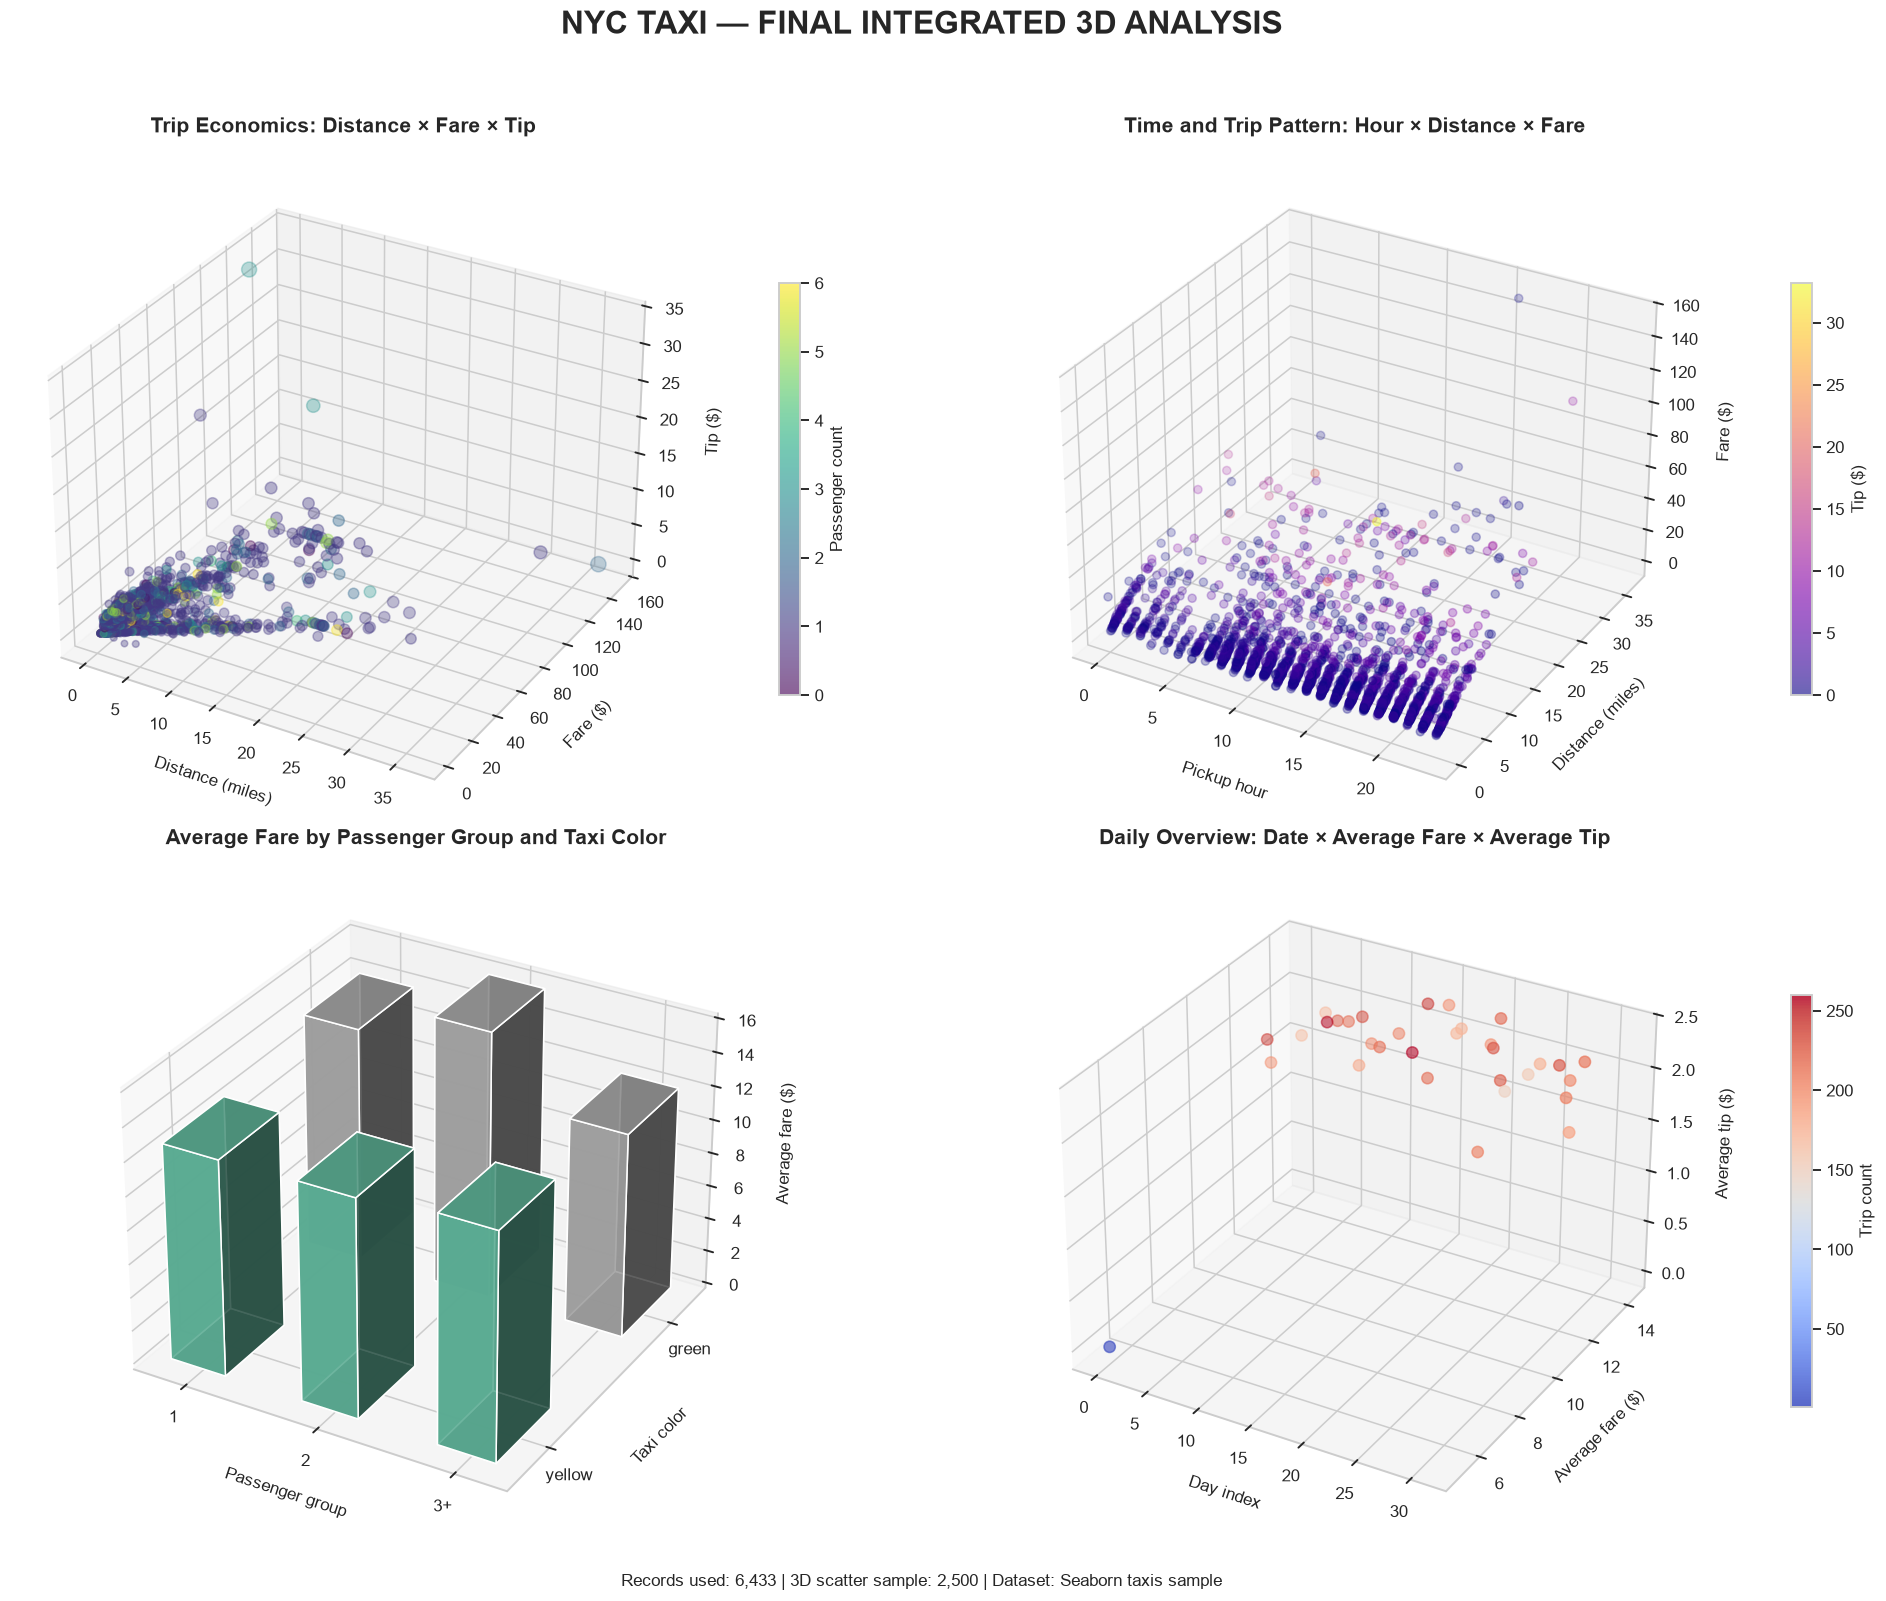

,Metric,Value
0,Total trips,6433.00
1,Average distance (miles),3.02
2,Average fare ($),13.09
3,Average tip ($),1.98
4,Average total amount ($),18.52
5,Average passengers,1.54
6,Average trip duration (minutes),14.35


Final 3D SVG: C:\Users\MARIO\Desktop\Data_Analysis\taxi_analysis\taxi_analysis_output\FINAL_3D_TAXI_ANALYSIS.svg
Final 3D PNG: C:\Users\MARIO\Desktop\Data_Analysis\taxi_analysis\taxi_analysis_output\FINAL_3D_TAXI_ANALYSIS.png


In [6]:
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

# Prepare a clean sample for readable 3D scatter plots
three_d_columns = ["distance", "fare", "tip", "total", "passengers", "pickup_hour"]
three_d_data = data[three_d_columns].replace([np.inf, -np.inf], np.nan).dropna().copy()
three_d_data = three_d_data[
    (three_d_data["distance"] >= 0) &
    (three_d_data["fare"] >= 0) &
    (three_d_data["tip"] >= 0) &
    (three_d_data["total"] >= 0)
]
plot_data = three_d_data.sample(min(2500, len(three_d_data)), random_state=42)

# Normalize marker sizes so extreme total amounts do not dominate the figure
size_values = plot_data["total"].clip(lower=0)
if size_values.max() > size_values.min():
    marker_sizes = 18 + 82 * (size_values - size_values.min()) / (size_values.max() - size_values.min())
else:
    marker_sizes = np.full(len(plot_data), 45)

fig = plt.figure(figsize=(19, 15))
fig.suptitle("NYC TAXI — FINAL INTEGRATED 3D ANALYSIS", fontsize=21, fontweight="bold", y=0.98)

# 3D view 1: distance, fare, and tip; color = passenger count; size = total amount
ax1 = fig.add_subplot(221, projection="3d")
sc1 = ax1.scatter(
    plot_data["distance"], plot_data["fare"], plot_data["tip"],
    c=plot_data["passengers"], cmap="viridis", s=marker_sizes, alpha=0.62
)
ax1.set_title("Trip Economics: Distance × Fare × Tip", pad=16)
ax1.set_xlabel("Distance (miles)", labelpad=9)
ax1.set_ylabel("Fare ($)", labelpad=9)
ax1.set_zlabel("Tip ($)", labelpad=9)
cb1 = fig.colorbar(sc1, ax=ax1, shrink=0.62, pad=0.10)
cb1.set_label("Passenger count")

# 3D view 2: pickup hour, distance, and fare; color = tip amount
ax2 = fig.add_subplot(222, projection="3d")
sc2 = ax2.scatter(
    plot_data["pickup_hour"], plot_data["distance"], plot_data["fare"],
    c=plot_data["tip"], cmap="plasma", s=28, alpha=0.62
)
ax2.set_title("Time and Trip Pattern: Hour × Distance × Fare", pad=16)
ax2.set_xlabel("Pickup hour", labelpad=9)
ax2.set_ylabel("Distance (miles)", labelpad=9)
ax2.set_zlabel("Fare ($)", labelpad=9)
cb2 = fig.colorbar(sc2, ax=ax2, shrink=0.62, pad=0.10)
cb2.set_label("Tip ($)")

# 3D view 3: average fare by passenger group and taxi color
summary_3d = data.dropna(subset=["passenger_group", "color", "fare"]).groupby(
    ["passenger_group", "color"], observed=False
)["fare"].mean().reset_index()
passenger_order = ["1 passenger", "2 passengers", "3+ passengers"]
color_order = list(data["color"].dropna().unique())
summary_3d["passenger_code"] = pd.Categorical(
    summary_3d["passenger_group"], categories=passenger_order, ordered=True
).codes
summary_3d["color_code"] = pd.Categorical(
    summary_3d["color"], categories=color_order, ordered=True
).codes
ax3 = fig.add_subplot(223, projection="3d")
bar_colors = plt.cm.Set2(np.linspace(0, 1, max(1, len(color_order))))
for _, row in summary_3d.iterrows():
    if row["passenger_code"] >= 0 and row["color_code"] >= 0:
        ax3.bar3d(
            row["passenger_code"] - 0.22, row["color_code"] - 0.22, 0,
            0.42, 0.42, row["fare"],
            color=bar_colors[int(row["color_code"])], alpha=0.88, shade=True
        )
ax3.set_title("Average Fare by Passenger Group and Taxi Color", pad=16)
ax3.set_xlabel("Passenger group", labelpad=9)
ax3.set_ylabel("Taxi color", labelpad=9)
ax3.set_zlabel("Average fare ($)", labelpad=9)
ax3.set_xticks(range(len(passenger_order)))
ax3.set_xticklabels(["1", "2", "3+"])
ax3.set_yticks(range(len(color_order)))
ax3.set_yticklabels([str(x) for x in color_order])

# 3D view 4: daily demand, average fare, and average tip over time
daily_3d = data.dropna(subset=["pickup_date", "fare", "tip"]).groupby("pickup_date").agg(
    trips=("fare", "size"), avg_fare=("fare", "mean"), avg_tip=("tip", "mean")
).reset_index()
daily_3d["day_index"] = np.arange(len(daily_3d))
ax4 = fig.add_subplot(224, projection="3d")
sc4 = ax4.scatter(
    daily_3d["day_index"], daily_3d["avg_fare"], daily_3d["avg_tip"],
    c=daily_3d["trips"], cmap="coolwarm", s=55, alpha=0.85
)
ax4.set_title("Daily Overview: Date × Average Fare × Average Tip", pad=16)
ax4.set_xlabel("Day index", labelpad=9)
ax4.set_ylabel("Average fare ($)", labelpad=9)
ax4.set_zlabel("Average tip ($)", labelpad=9)
cb4 = fig.colorbar(sc4, ax=ax4, shrink=0.62, pad=0.10)
cb4.set_label("Trip count")

fig.text(
    0.5, 0.025,
    f"Records used: {len(three_d_data):,} | 3D scatter sample: {len(plot_data):,} | "
    "Dataset: Seaborn taxis sample",
    ha="center", fontsize=11
)
fig.tight_layout(rect=[0, 0.045, 1, 0.95])

final_3d_svg = OUTPUT_DIR / "FINAL_3D_TAXI_ANALYSIS.svg"
final_3d_png = OUTPUT_DIR / "FINAL_3D_TAXI_ANALYSIS.png"
fig.savefig(final_3d_svg, format="svg", bbox_inches="tight")
fig.savefig(final_3d_png, format="png", dpi=220, bbox_inches="tight")
plt.show()

# A concise final numerical summary to accompany the 3D visuals
final_summary = pd.DataFrame({
    "Metric": [
        "Total trips", "Average distance (miles)", "Average fare ($)",
        "Average tip ($)", "Average total amount ($)",
        "Average passengers", "Average trip duration (minutes)"
    ],
    "Value": [
        len(data), data["distance"].mean(), data["fare"].mean(),
        data["tip"].mean(), data["total"].mean(),
        data["passengers"].mean(),
        data.loc[data["duration_min"].between(0, 180), "duration_min"].mean()
    ]
})
display(final_summary.round(2))
print("Final 3D SVG:", final_3d_svg.resolve())
print("Final 3D PNG:", final_3d_png.resolve())